In [138]:
import os

from openai import OpenAI

import numpy as np
import matplotlib.pyplot as plt

In [145]:
alt_key = os.getenv('OPENAI_API_KEY')
print(alt_key[-4:])
client = OpenAI(api_key=alt_key)

NcAA


In [146]:
client.responses.create(
    model='gpt-6-luna',
    input='hi'
)

Response(id='resp_0ac33ecf0dd6e368006ad67884ec0c87d0a776d63f52166f0f', created_at=1792440452.0, error=None, incomplete_details=None, instructions=None, metadata={}, model='gpt-6-luna', object='response', output=[ResponseReasoningItem(id='rs_0ac33ecf0dd6e368006ad678865e2c87d08ae72844e6a3b852', summary=[], type='reasoning', content=[], encrypted_content='gAAAAABq1niG00i4auyGdIL845HjGQRxPKXlE_Mr1Q9ZVFk4_FgUFkS45f6o9FHx_8f8QNYa0-yD5CRB9qj9LLurSjlsYKqeGEzGA02rtUbP6CwMB1n_-Ml8jXwWQYK8csh1lJTMDhST_HoPUIeHS4hmPYIMbJK3zcLOWf1I4htJSSByhbtBRD4Phg77Xay_p0XpBpz9KC1VxU2pn09mN_MbvwMBjsUMcsYhiIjWF9xTOHJrGjVwcOuehoqohZJnPJKawY2-Wm5c-V70qAO5qnkTQpcr7TmTYwwVuVK9mdo8yw_suBVmQnG-LsUATMCKUCsx__CWePiTxmXCUwKdYCaKrBGsCMz_2bbSCG_InW0waALFLLl8SdaGlVv7ICkaQ-i8N0oyfJQjrYqcUd_1TezDi95DiClJc2wev-rJz5tQPTu01-BjTUUnvSImlw3ySjxbghhyVTfESSmqSFFCRPUYQ82-TRcTMq1i5txUH4uqgR4-apUAxQkIjxGyvAuziJntqUOYpDhb5JNs1pU6QtB_p-x9VU-nebwPDOnJMXDn_5fnhEmJuN4EvCzPAk_nC40mUBCfDNhs40R7YDIwUy0cOsYFMVom7TJu6NHGdPx3MYiGLmGSQkj7uMcZqh8y5db25

In [147]:
response = client.embeddings.create(
    model='text-embedding-3-small',
    input=['hi']
)

In [79]:
response

CreateEmbeddingResponse(data=[Embedding(embedding=[-0.00374603271484375, -0.0191650390625, 0.01221466064453125, 0.032745361328125, 0.016204833984375, -0.03717041015625, -0.02825927734375, 0.06494140625, 0.0009541511535644531, -0.057525634765625, 0.0014677047729492188, -0.03265380859375, -0.03076171875, 0.004787445068359375, 0.03289794921875, 0.019287109375, -0.04193115234375, -0.002918243408203125, 0.024688720703125, 0.046661376953125, 0.03778076171875, 0.0341796875, -0.00246429443359375, 0.0362548828125, 0.0163116455078125, 0.001827239990234375, 0.002094268798828125, -0.00887298583984375, 0.032073974609375, -0.0263214111328125, 0.0013322830200195312, -0.03778076171875, 0.0258331298828125, -0.037017822265625, -0.01654052734375, -0.0127105712890625, -0.025634765625, 0.03302001953125, 0.015533447265625, -0.037811279296875, 0.024993896484375, -0.00499725341796875, 0.046417236328125, 0.015869140625, -0.019866943359375, 0.015655517578125, -0.026947021484375, 0.0164031982421875, 0.0038490295

In [80]:
data = np.array([item.embedding for item in response.data])

In [81]:
data.shape

(1, 1536)

In [82]:
data

array([[-0.00374603, -0.01916504,  0.01221466, ..., -0.02490234,
        -0.01898193,  0.00306702]])

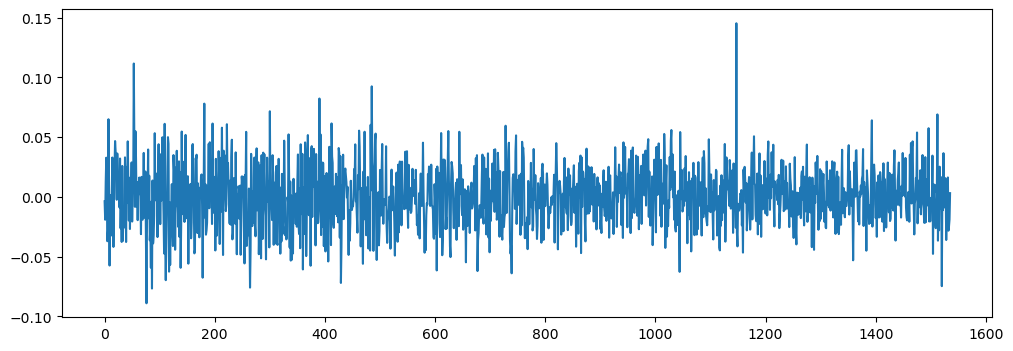

In [83]:
plt.figure(figsize=(12, 4))
plt.plot(data.T)

In [85]:
data @ data.T

array([[0.99974318]])

In [86]:
def embed(content: list[str]) -> np.array:
    response = client.embeddings.create(
        input=content,
        model='text-embedding-3-small'
    )
    return np.array([emb.embedding for emb in response.data])

In [87]:
data = embed(['hi', 'hello'])

In [88]:
data.shape

(2, 1536)

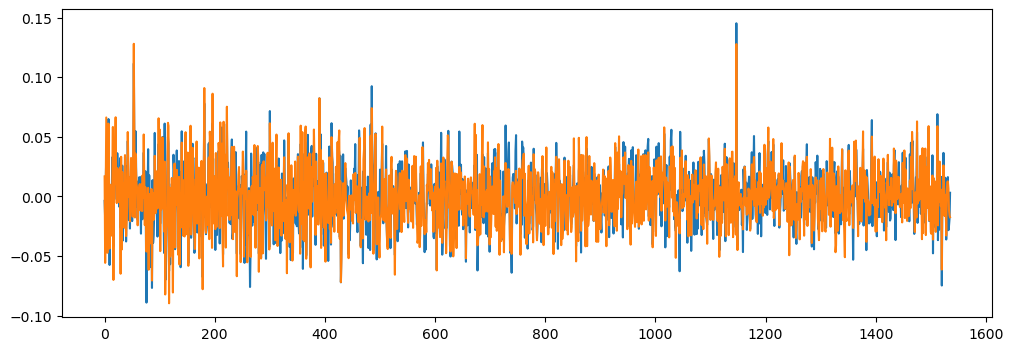

In [89]:
plt.figure(figsize=(12, 4))
plt.plot(data.T)

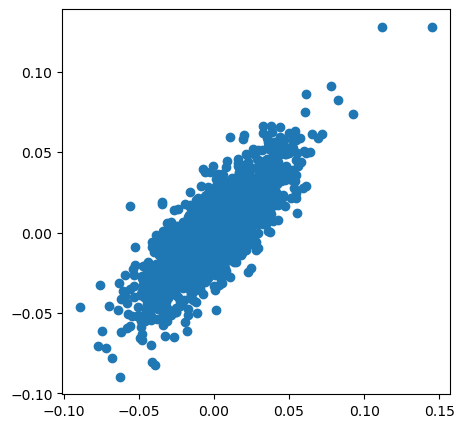

In [90]:
plt.figure(figsize=(5, 5))
plt.scatter(x=data[0], y=data[1])

In [91]:
data @ data.T

array([[0.99974318, 0.80824872],
       [0.80824872, 0.99969776]])

In [92]:
text = [
    'hi', 'hello', 'hola', 'oi', 'good bye', 'nihao', "'sup", 
    'I like cheese!', 'Me gusta el queso!', 'thermodynamics', 
    '2 * 7 = 4'
]

In [93]:
data = embed(text)
sims = data @ data.T

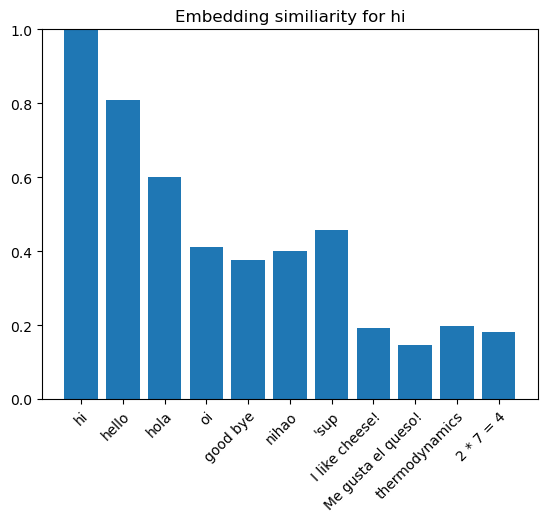

In [94]:
index = 0
ax = plt.bar(x=range(len(text)), height=sims[index,:])
plt.xticks(range(len(text)), text, rotation=45, ha='right', rotation_mode='anchor')
plt.title('Embedding similiarity for ' + text[index])
plt.ylim([0, 1]);

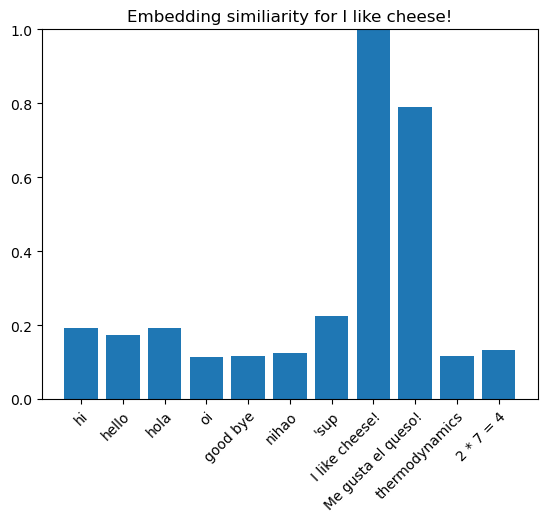

In [95]:
index = 7
ax = plt.bar(x=range(len(text)), height=sims[index,:])
plt.xticks(range(len(text)), text, rotation=45, ha='right', rotation_mode='anchor')
plt.title('Embedding similiarity for ' + text[index])
plt.ylim([0, 1]);

## Lookup

In [ ]:
!pwd

In [96]:
from pathlib import Path

content_dir = Path('../../../../../cs301R/gospel-connections/data/text/1-ne/')

content_verses = []
for content_file in sorted(content_dir.glob('*.txt'), key=lambda f: f.name):
    content_verses += content_file.read_text().splitlines()

In [97]:
content_verses

['I, Nephi, having been born of goodly parents, therefore I was taught somewhat in all the learning of my father; and having seen many afflictions in the course of my days, nevertheless, having been highly favored of the Lord in all my days; yea, having had a great knowledge of the goodness and the mysteries of God, therefore I make a record of my proceedings in my days.',
 'Yea, I make a record in the language of my father, which consists of the learning of the Jews and the language of the Egyptians.',
 'And I know that the record which I make is true; and I make it with mine own hand; and I make it according to my knowledge.',
 'For it came to pass in the commencement of the first year of the reign of Zedekiah, king of Judah, (my father, Lehi, having dwelt at Jerusalem in all his days); and in that same year there came many prophets, prophesying unto the people that they must repent, or the great city Jerusalem must be destroyed.',
 'Wherefore it came to pass that my father, Lehi, as

In [98]:
content_embeds = embed(content_verses)

In [99]:
content_embeds.shape

(618, 1536)

In [100]:
query = embed(['build boat'])

In [101]:
query.shape

(1, 1536)

In [102]:
sims = query @ content_embeds.T
sims

array([[ 5.85818647e-02,  7.24256361e-02,  9.07335458e-02,
         5.16676279e-02,  9.66749673e-02,  7.50481293e-02,
         5.70468777e-02,  5.19008839e-02,  1.77074991e-02,
         1.34403165e-02,  6.19967751e-02,  8.89783436e-02,
         4.99096601e-02,  4.01512451e-02,  8.04315331e-02,
         6.32785069e-02,  1.73177438e-01,  5.73758007e-02,
         4.07901081e-02,  3.93812782e-02,  8.01782432e-02,
         8.52219693e-02,  5.54194174e-02,  8.20224034e-02,
         1.17458023e-01,  1.11535555e-01,  1.24904440e-01,
         1.36712273e-01,  1.36355108e-01,  8.19197727e-02,
         8.50121289e-02,  7.04625073e-02,  2.45103930e-02,
         4.59701733e-02,  1.33062586e-01,  5.56692908e-02,
         5.35244732e-02,  6.51638722e-02,  3.67349288e-02,
         8.48905410e-02,  4.10385658e-02,  6.09411897e-02,
         1.48124308e-02,  3.12182899e-02,  2.06109054e-02,
         4.78602412e-02,  8.57674805e-02,  8.54411990e-02,
         6.89428467e-02,  7.06733232e-02,  7.24011944e-0

(-30.85, 647.85)

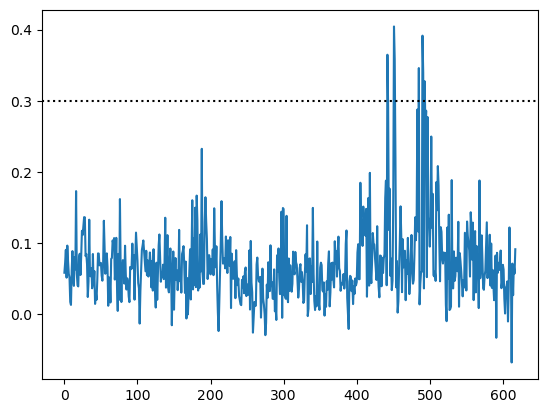

In [103]:
plt.plot(sims.T)
xlim = plt.xlim()
plt.plot(plt.xlim(), [0.3, 0.3], c='k', ls=':')
plt.xlim(xlim)

In [104]:
def get_verses(phrase, threshold = 0.6):
    embedding = embed([phrase])
    scores = content_embeds @ embedding.T
    return np.array(content_verses)[scores.flatten() > threshold]

In [105]:
verses = get_verses('create boat', threshold=0.3)
print('\n\n'.join(verses))

And it came to pass that the Lord spake unto me, saying: Thou shalt construct a ship, after the manner which I shall show thee, that I may carry thy people across these waters.

And when my brethren saw that I was about to build a ship, they began to murmur against me, saying: Our brother is a fool, for he thinketh that he can build a ship; yea, and he also thinketh that he can cross these great waters.

And thus my brethren did complain against me, and were desirous that they might not labor, for they did not believe that I could build a ship; neither would they believe that I was instructed of the Lord.

And now, if the Lord has such great power, and has wrought so many miracles among the children of men, how is it that he cannot instruct me, that I should build a ship?

And it came to pass that they did worship the Lord, and did go forth with me; and we did work timbers of curious workmanship. And the Lord did show me from time to time after what manner I should work the timbers of 

In [106]:
verses = get_verses('he talked with god and learned', threshold=0.45)
print('\n\n'.join(verses))

And it came to pass as he prayed unto the Lord, there came a pillar of fire and dwelt upon a rock before him; and he saw and heard much; and because of the things which he saw and heard he did quake and tremble exceedingly.

And being thus overcome with the Spirit, he was carried away in a vision, even that he saw the heavens open, and he thought he saw God sitting upon his throne, surrounded with numberless concourses of angels in the attitude of singing and praising their God.

And after this manner was the language of my father in the praising of his God; for his soul did rejoice, and his whole heart was filled, because of the things which he had seen, yea, which the Lord had shown unto him.

And I said unto him: To know the interpretation thereof--for I spake unto him as a man speaketh; for I beheld that he was in the form of a man; yet nevertheless, I knew that it was the Spirit of the Lord; and he spake unto me as a man speaketh with another.

And he said unto me: Knowest thou th

In [107]:
verses = get_verses('hable con dios', threshold=0.35)
print('\n\n'.join(verses))

And it came to pass that the Lord spake unto me, saying: Blessed art thou, Nephi, because of thy faith, for thou hast sought me diligently, with lowliness of heart.

And it came to pass that I spake with him, that if he would hearken unto my words, as the Lord liveth, and as I live, even so that if he would hearken unto our words, we would spare his life.

And it had come to pass that my father spake unto her, saying: I know that I am a visionary man; for if I had not seen the things of God in a vision I should not have known the goodness of God, but had tarried at Jerusalem, and had perished with my brethren.

Yea, even he should go forth and cry in the wilderness: Prepare ye the way of the Lord, and make his paths straight; for there standeth one among you whom ye know not; and he is mightier than I, whose shoe's latchet I am not worthy to unloose. And much spake my father concerning this thing.

And when I had spoken these words, the Spirit cried with a loud voice, saying: Hosanna t

In [108]:
verses = get_verses('and thus have I accomplished all that was accounted me before my teacher', threshold=0.35)
print('\n\n'.join(verses))

I, Nephi, having been born of goodly parents, therefore I was taught somewhat in all the learning of my father; and having seen many afflictions in the course of my days, nevertheless, having been highly favored of the Lord in all my days; yea, having had a great knowledge of the goodness and the mysteries of God, therefore I make a record of my proceedings in my days.

And I know that the record which I make is true; and I make it with mine own hand; and I make it according to my knowledge.

And it came to pass that when my father had read and seen many great and marvelous things, he did exclaim many things unto the Lord; such as: Great and marvelous are thy works, O Lord God Almighty! Thy throne is high in the heavens, and thy power, and goodness, and mercy are over all the inhabitants of the earth; and, because thou art merciful, thou wilt not suffer those who come unto thee that they shall perish!

And after this manner was the language of my father in the praising of his God; for 

In [109]:
content_embeds = embed(content_verses)

In [110]:
content_embeds.shape

(618, 1536)

In [111]:
median = np.median(content_embeds, axis=0)

In [112]:
median

array([ 0.01093674,  0.0187912 , -0.00250626, ..., -0.0056839 ,
       -0.00793457, -0.00255299])

In [113]:
normed_embeds = content_embeds - median

In [114]:
def get_verses_normed(phrase, threshold = 0.6):
    embedding = embed([phrase])
    scores = normed_embeds @ embedding.T
    return np.array(content_verses)[scores.flatten() > threshold]

In [116]:
verses = get_verses_normed(
    'and thus have I accomplished all that was accounted me before my teacher', 
    threshold=0.2
)
print('\n\n'.join(verses))

And thus my father had fulfilled all the commandments of the Lord which had been given unto him. And also, I, Nephi, had been blessed of the Lord exceedingly.


In [125]:
scores = normed_embeds @ median
np.array(content_verses)[scores.flatten() > 0.09]

array(['And it came to pass that I beheld many multitudes of the Gentiles upon the land of promise; and I beheld the wrath of God, that it was upon the seed of my brethren; and they were scattered before the Gentiles and were smitten.'],
      dtype='<U715')

In [124]:
np.max(scores)

0.09379317769154483

In [131]:
foo = embed(text:=['king', 'man', 'queen', 'woman'])

In [132]:
foo.shape

(4, 1536)

In [133]:
sims = foo @ foo.T

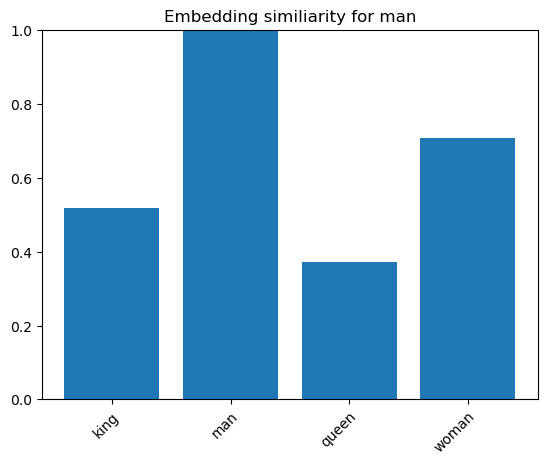

In [134]:
index = 1
ax = plt.bar(x=range(len(text)), height=sims[index,:])
plt.xticks(range(len(text)), text, rotation=45, ha='right', rotation_mode='anchor')
plt.title('Embedding similiarity for ' + text[index])
plt.ylim([0, 1]);

In [135]:
queen = foo[0] - foo[1] + foo[3]

In [136]:
queen @ foo.T

array([0.896743  , 0.22598316, 0.7235167 , 0.70744198])

In [137]:
embed(['agioua'])

array([[ 1.68609619e-02,  7.98702240e-06, -1.58996582e-02, ...,
         1.54266357e-02, -1.17034912e-02,  2.12402344e-02]])